In [1]:
# ====== Core Python Libraries ======
import os
import re

# ====== Data Handling ======
import numpy as np
import pandas as pd

# ====== Visualization ======
import matplotlib.pyplot as plt
import seaborn as sns

# ====== NLP (NLTK) ======
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ====== Scikit-learn: Model Selection ======
from sklearn.model_selection import train_test_split

# ====== Scikit-learn: Feature Extraction ======
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer,
    HashingVectorizer
)

# ====== Scikit-learn: Preprocessing ======
from sklearn.preprocessing import StandardScaler

# ====== Scikit-learn: Machine Learning Models ======
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)

# ====== Boosting Libraries ======
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# ====== Scikit-learn: Evaluation Metrics ======
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ====== Sparse Matrix Utilities ======
from scipy.sparse import csr_matrix, hstack

# ====== Model Saving ======
import joblib

# ====== Progress Bar ======
from tqdm import tqdm

In [2]:
# Download required NLTK data (run once)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

In [4]:
# Create models directory if it doesn't exist
os.makedirs('models', exist_ok=True)

In [5]:
df = pd.read_csv(r"C:\Users\dheer\OneDrive\Desktop\major_project\major_project\Dataset\benchmark_results.csv")

In [6]:
df

,QueryID,Level,NL_Query,Expected_SQL,Generated_SQL,Execution_Success,Generated_Rows,Expected_Rows,Exact_Match,Value_Match_Pct,Row_Match_Pct,Col_Match_Pct,Confidence_Score,Operation_Match,Column_Match,Generation_Time_s
0,1,Simple,Show all sales from the North region,SELECT * FROM data WHERE Region = 'North',SELECT * FROM data WHERE Region = 'North',True,206,206,True,100,100.0,100.0,100.0,100.0,100.0,28.68
1,2,Simple,List all products sold in 2024,SELECT * FROM data WHERE Year = 2024,SELECT DISTINCT Product\nFROM data\nWHERE Year...,True,10,346,False,0,2.9,5.9,100.0,100.0,100.0,5.43
2,3,Simple,Show orders with total sales above 5000,SELECT * FROM data WHERE TotalSales > 5000,SELECT * FROM data WHERE TotalSales > 5000,True,344,344,True,100,100.0,100.0,66.7,0.0,100.0,4.73
3,4,Simple,Display all laptop orders,SELECT * FROM data WHERE Product = 'Laptop',SELECT * FROM data WHERE Product = 'Laptop',True,86,86,True,100,100.0,100.0,93.3,100.0,80.0,3.49
4,5,Simple,List the first 10 records,SELECT * FROM data LIMIT 10,SELECT * FROM data LIMIT 10,True,10,10,True,100,100.0,100.0,93.3,100.0,80.0,3.35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,96,Complex,Show regions where all products have been sold,SELECT Region FROM data GROUP BY Region HAVING...,SELECT Region FROM data GROUP BY Region HAVING...,True,5,5,True,100,100.0,100.0,66.7,100.0,100.0,7.72
396,97,Complex,Average order value trend by quarter and year,"SELECT Year, Quarter, AVG(TotalSales) FROM dat...","SELECT\n STRFTIME('%Y', Date) AS Year,\n STR...",True,36,12,False,0,0.0,66.7,100.0,100.0,100.0,16.93
397,98,Complex,Cumulative sum of quantity sold per product or...,"SELECT Product, Date, Quantity, SUM(Quantity) ...","SELECT\n Date,\n Product,\n SUM(Quantity) O...",True,1000,1000,False,0,100.0,50.0,75.0,50.0,100.0,8.56
398,99,Complex,Products that are only sold through online cus...,SELECT Product FROM data GROUP BY Product HAVI...,SELECT DISTINCT Product\nFROM data\nWHERE Cust...,True,10,0,False,50,0.0,100.0,100.0,100.0,100.0,150.01


In [7]:

class_names = [str(x) for x in sorted(df['Execution_Success'].unique())]
print("Classes:", class_names)

Classes: ['False', 'True']


In [8]:
def preprocess_text(text):
    """
    NLP Preprocessing: lowercase, remove punctuation, remove stopwords, lemmatize.
    """
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
    stop_words = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()
    words = text.split()
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    return ' '.join(words)

In [9]:
def get_preprocessed_data(df, target_col):
    preprocessed_path = 'models/preprocessed.pkl'

    if os.path.exists(preprocessed_path):
        print("Loading preprocessed data...")
        return joblib.load(preprocessed_path)
    else:
        print("Preprocessing text...")

        processed_cols = {}

        numeric_df = df.select_dtypes(include=['number'])
        target_df = df[[target_col]]

        for col in df.columns:
            if col != target_col and df[col].dtype == object:
                processed_cols[f"{col}_processed"] = [
                    preprocess_text(text) for text in tqdm(
                        df[col].astype(str),
                        desc=f"Preprocessing {col}"
                    )
                ]

        processed_text_df = pd.DataFrame(processed_cols)

        final_df = pd.concat([
            numeric_df.reset_index(drop=True),
            processed_text_df.reset_index(drop=True),
            target_df.reset_index(drop=True)
        ], axis=1)

        joblib.dump(final_df, preprocessed_path)
        print("Preprocessed data saved.")

        return final_df

In [10]:
df = get_preprocessed_data(df, target_col='Execution_Success')
df

Preprocessing text...


Preprocessing Generated_SQL: 100%|██████████████████████████████████████████████████| 400/400 [00:00<00:00, 519.42it/s]


Preprocessed data saved.


,QueryID,Generated_Rows,Expected_Rows,Value_Match_Pct,Row_Match_Pct,Col_Match_Pct,Confidence_Score,Operation_Match,Column_Match,Generation_Time_s,Level_processed,NL_Query_processed,Expected_SQL_processed,Generated_SQL_processed,Execution_Success
0,1,206,206,100,100.0,100.0,100.0,100.0,100.0,28.68,simple,show sale north region,select data region north,select data region north,True
1,2,10,346,0,2.9,5.9,100.0,100.0,100.0,5.43,simple,list product sold,select data year,select distinct product data year,True
2,3,344,344,100,100.0,100.0,66.7,0.0,100.0,4.73,simple,show order total sale,select data totalsales,select data totalsales,True
3,4,86,86,100,100.0,100.0,93.3,100.0,80.0,3.49,simple,display laptop order,select data product laptop,select data product laptop,True
4,5,10,10,100,100.0,100.0,93.3,100.0,80.0,3.35,simple,list first record,select data limit,select data limit,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,96,5,5,100,100.0,100.0,66.7,100.0,100.0,7.72,complex,show region product sold,select region data group region countdistinct ...,select region data group region countdistinct ...,True
396,97,36,12,0,0.0,66.7,100.0,100.0,100.0,16.93,complex,average order value trend quarter year,select year quarter avgtotalsales data group y...,select strftimey date year strftimem date mont...,True
397,98,1000,1000,0,100.0,50.0,75.0,50.0,100.0,8.56,complex,cumulative sum quantity sold per product order...,select product date quantity sumquantity parti...,select date product sumquantity partition prod...,True
398,99,10,0,50,0.0,100.0,100.0,100.0,100.0,150.01,complex,product sold online customer,select product data group product countdistinc...,select distinct product data customertype online,True


In [11]:
def get_vectorized_data(df, target_col, method="Uni-Gram"):

    safe_method = method.replace(" ", "_").replace("-", "_")

    tfidf_path = f"models/vectorized_{safe_method}.pkl"
    vectorizer_path = f"models/vectorizer_{safe_method}.pkl"
    scaler_path = f"models/scaler.pkl"

    if os.path.exists(tfidf_path) and os.path.exists(vectorizer_path):
        print("Loading vectorized data...")
        X = joblib.load(tfidf_path)
        vectorizer = joblib.load(vectorizer_path)
        scaler = joblib.load(scaler_path) if os.path.exists(scaler_path) else None
        return X, vectorizer, scaler

    print(f"Computing vectorization using method: {method}")

    text_cols = [col for col in df.columns if col.endswith('_processed')]
    num_df = df.select_dtypes(include=['number'])

    merged_text = df[text_cols].fillna('').agg(' '.join, axis=1)

    if method == "Uni-Gram":
        vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 1))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Bi-Gram":
        vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Char-Gram":
        vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5))
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Count-Vec":
        vectorizer = CountVectorizer(max_features=5000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Hash-Vec":
        vectorizer = HashingVectorizer(n_features=5000, alternate_sign=False)
        X_text = vectorizer.transform(merged_text)

    elif method == "Sublinear-TF":
        vectorizer = TfidfVectorizer(sublinear_tf=True, max_features=6000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "TFIDF-BiTri":
        vectorizer = TfidfVectorizer(ngram_range=(2, 3), max_features=7000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Binary-Count":
        vectorizer = CountVectorizer(binary=True, max_features=6000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "CharWide-Gram":
        vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 7), max_features=8000)
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "Light-Hash":
        vectorizer = HashingVectorizer(n_features=10000, alternate_sign=False)
        X_text = vectorizer.transform(merged_text)

    elif method == "Bag-of-Words":
        vectorizer = CountVectorizer(max_features=7000, stop_words='english')
        X_text = vectorizer.fit_transform(merged_text)

    elif method == "BM25-Style":
        vectorizer = TfidfVectorizer(
            max_features=8000,
            norm=None,
            use_idf=True,
            smooth_idf=True,
            sublinear_tf=True
        )
        X_text = vectorizer.fit_transform(merged_text)

    else:
        raise ValueError("Invalid method selected")

    if num_df.shape[1] > 0:
        scaler = StandardScaler()
        X_num_scaled = scaler.fit_transform(num_df.values)
        X_num_sparse = csr_matrix(X_num_scaled)
        X = hstack([X_text, X_num_sparse])
        joblib.dump(scaler, scaler_path)
    else:
        print("⚠️ No numerical columns found — using only NLP features")
        X = X_text
        scaler = None

    joblib.dump(X, tfidf_path)
    joblib.dump(vectorizer, vectorizer_path)

    print("Final feature matrix X saved successfully.")
    return X, vectorizer, scaler

In [12]:
X, vectorizer, scaler = get_vectorized_data(df, target_col='Execution_Success', method="Bag-of-Words")


Computing vectorization using method: Bag-of-Words
Final feature matrix X saved successfully.


In [13]:
y = df['Execution_Success']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (320, 181) Test shape: (80, 181)


In [14]:
def evaluate_model(y_test, y_pred, class_names):
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"Accuracy (A):  {acc:.4f}")
    print(f"Precision (P): {precision:.4f}")
    print(f"Recall (R):    {recall:.4f}")
    print(f"F1-Score:      {f1:.4f}")

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title("Confusion Matrix")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.show()

    print("\nClassification Report (CR):\n")
    print(classification_report( y_test,y_pred,target_names=[str(x) for x in class_names]))


In [15]:
def train_or_load_model(X_train, y_train, X_test, model_name):
    os.makedirs("models", exist_ok=True)
    model_path = f"models/{model_name}.npz"

    if os.path.exists(model_path):
        print(f"✅ Loading saved model: {model_name}")
        model = joblib.load(model_path)

    else:
        print(f"🚀 Training new model: {model_name}")

        if model_name == "LogisticRegression":
            model = LogisticRegression(max_iter=1000)

        elif model_name == "SVM":
            model = SVC(probability=True)

        elif model_name == "RandomForest":
            model = RandomForestClassifier(n_estimators=200)

        elif model_name == "ExtraTrees":
            model = ExtraTreesClassifier(n_estimators=200)

        elif model_name == "GradientBoosting":
            model = GradientBoostingClassifier()

        elif model_name == "AdaBoost":
            model = AdaBoostClassifier()

        elif model_name == "KNN":
            model = KNeighborsClassifier(n_neighbors=5)

        elif model_name == "NaiveBayes":
            model = GaussianNB()
            
            # Convert sparse matrices to dense
            X_train = X_train.toarray()
            X_test = X_test.toarray()

        elif model_name == "XGBoost":
            model = XGBClassifier(use_label_encoder=False, eval_metric="mlogloss")

        elif model_name == "LightGBM":
            model = LGBMClassifier()

        else:
            raise ValueError("Invalid model name selected")

        model.fit(X_train, y_train)
        joblib.dump(model, model_path)
        print(f"✅ Model saved: {model_path}")

    y_pred = model.predict(X_test)
    return model, y_pred


🚀 Training new model: RandomForest
✅ Model saved: models/RandomForest.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


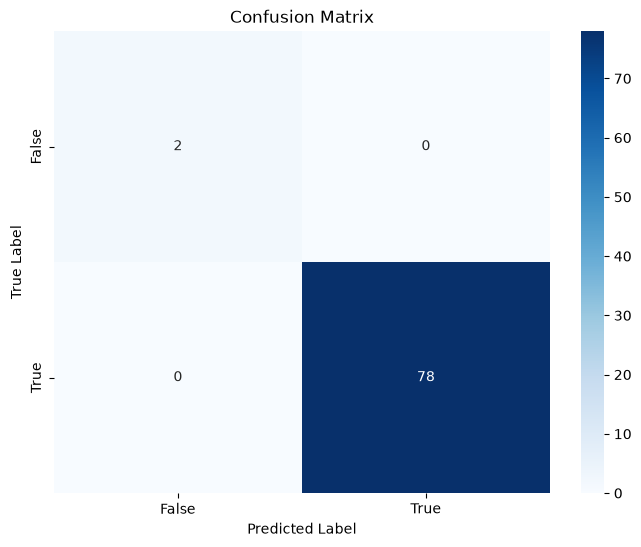


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [16]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "RandomForest")
evaluate_model(y_test, RFC_y_pred, class_names)

🚀 Training new model: LogisticRegression
✅ Model saved: models/LogisticRegression.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


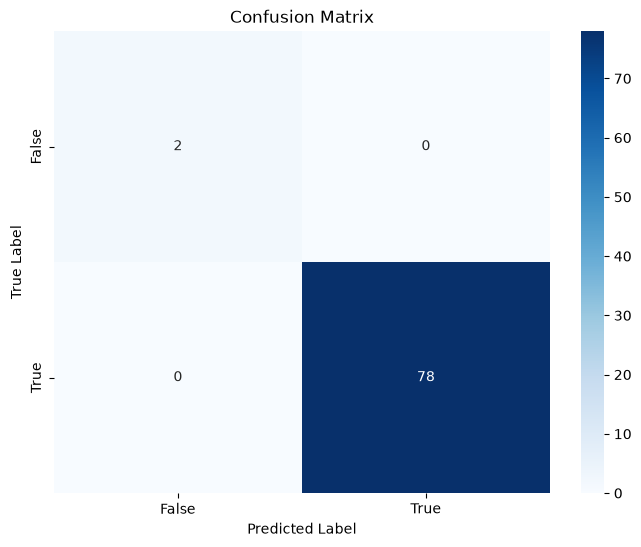


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [17]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "LogisticRegression")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: SVM
✅ Model saved: models/SVM.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


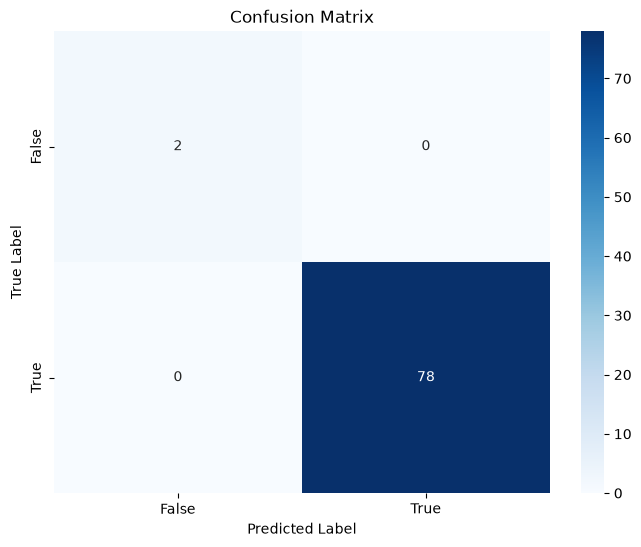


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [18]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "SVM")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: ExtraTrees
✅ Model saved: models/ExtraTrees.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


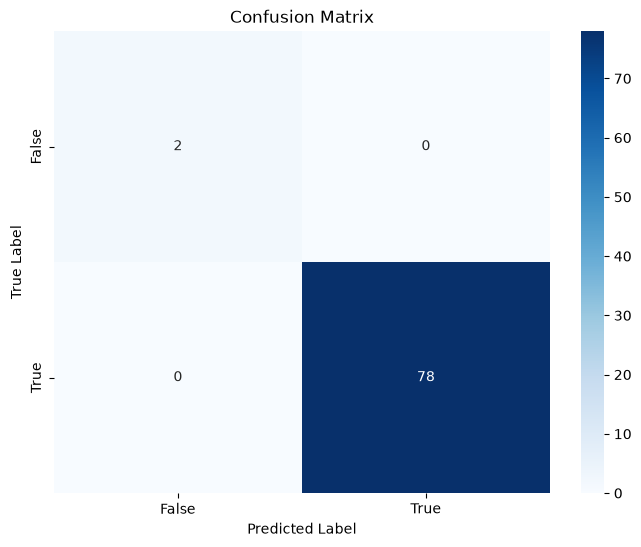


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [19]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "ExtraTrees")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: GradientBoosting
✅ Model saved: models/GradientBoosting.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


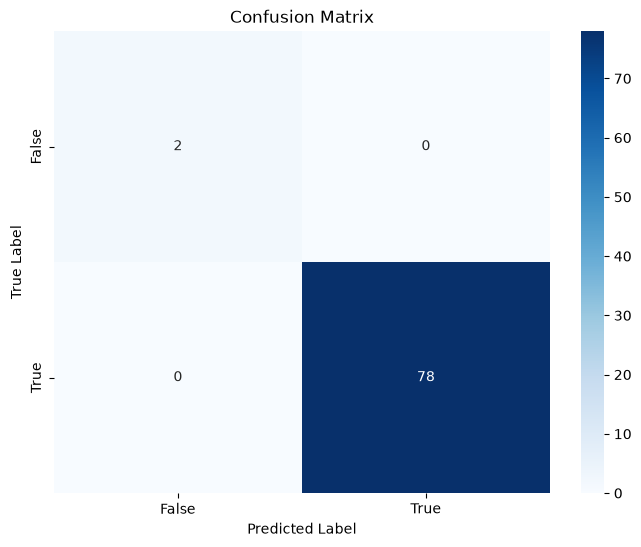


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [20]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "GradientBoosting")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: AdaBoost
✅ Model saved: models/AdaBoost.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


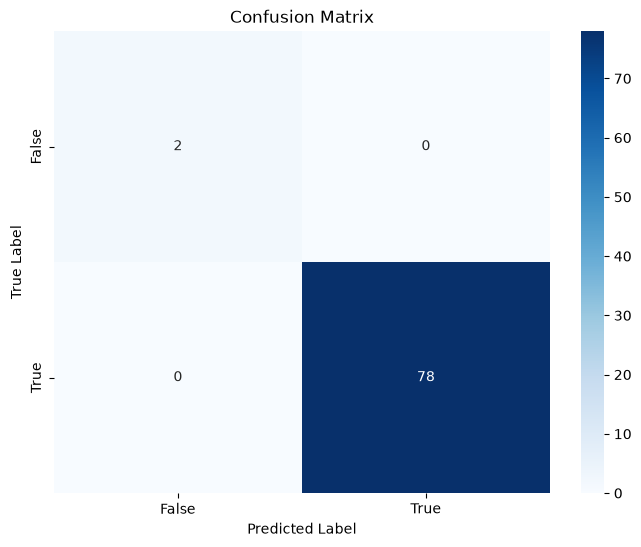


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [21]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "AdaBoost")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: KNN
✅ Model saved: models/KNN.npz
Accuracy (A):  0.9750
Precision (P): 0.9506
Recall (R):    0.9750
F1-Score:      0.9627


C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


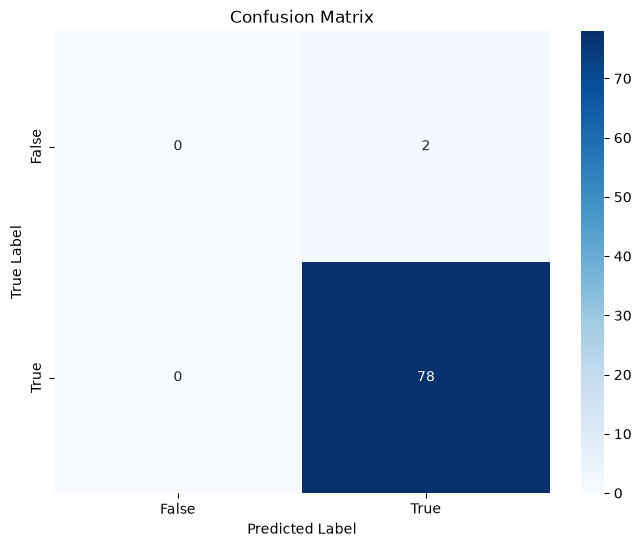


Classification Report (CR):

              precision    recall  f1-score   support

       False       0.00      0.00      0.00         2
        True       0.97      1.00      0.99        78

    accuracy                           0.97        80
   macro avg       0.49      0.50      0.49        80
weighted avg       0.95      0.97      0.96        80



C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [22]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "KNN")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: NaiveBayes
✅ Model saved: models/NaiveBayes.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


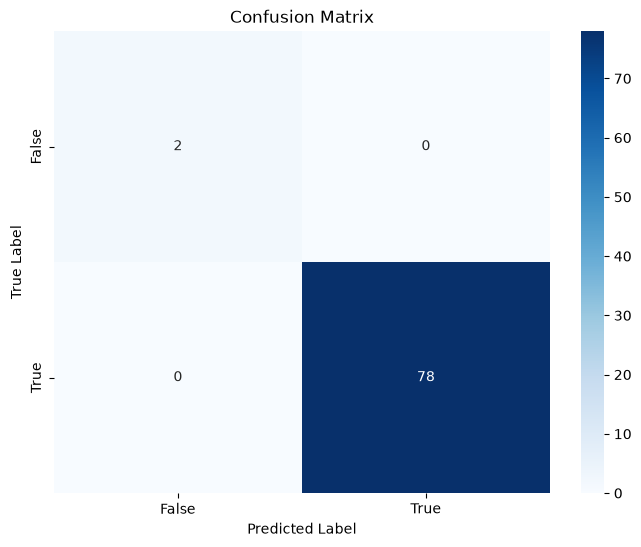


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [23]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "NaiveBayes")
evaluate_model(y_test, RFC_y_pred, class_names)

🚀 Training new model: XGBoost
✅ Model saved: models/XGBoost.npz
Accuracy (A):  1.0000
Precision (P): 1.0000
Recall (R):    1.0000
F1-Score:      1.0000


C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\xgboost\training.py:183: UserWarning: [23:12:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


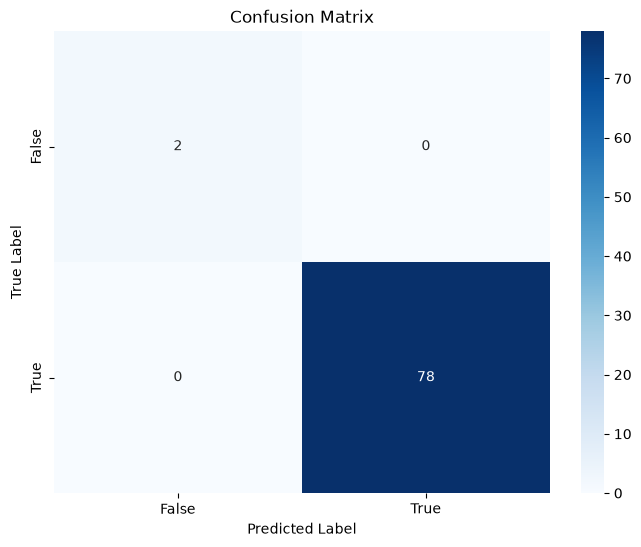


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [24]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "XGBoost")
evaluate_model(y_test, RFC_y_pred, class_names)



🚀 Training new model: LightGBM
[LightGBM] [Info] Number of positive: 310, number of negative: 10
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000793 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 425
[LightGBM] [Info] Number of data points in the train set: 320, number of used features: 46
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.968750 -> initscore=3.433987
[LightGBM] [Info] Start training from score 3.433987
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\dheer\.conda\envs\py3120\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\dheer\.conda\envs\py3120\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\dheer\.conda\envs\py3120\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\dheer\.conda\envs\py3120\Lib\subprocess.py", line 1538, in _execute_c

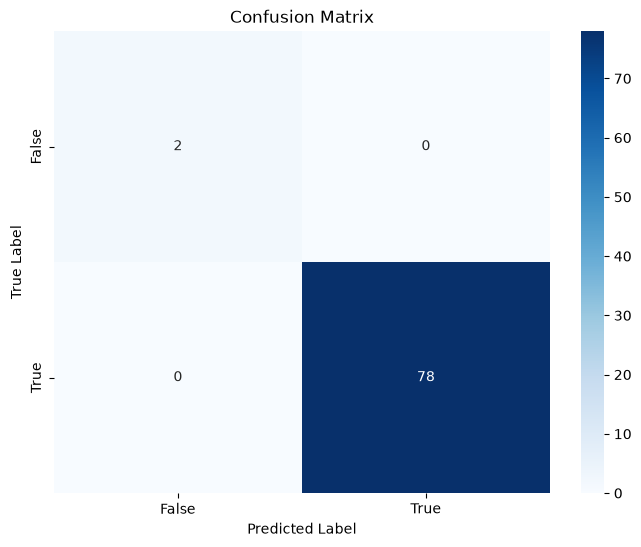


Classification Report (CR):

              precision    recall  f1-score   support

       False       1.00      1.00      1.00         2
        True       1.00      1.00      1.00        78

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [25]:
RFC_model, RFC_y_pred =train_or_load_model(X_train, y_train, X_test, "LightGBM")
evaluate_model(y_test, RFC_y_pred, class_names)

